# 02 — Data Preprocessing
Мета: підготувати зображення та annotations для подальшого навчання object detection моделей.

## 0. Setup and configuration
`BATCH_SIZE` — кількість кадрів у групі <br>
`NUM_CLASSES` = 9: вісім класів і background (0)

In [2]:
from pathlib import Path
from collections import defaultdict
import json
import random

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import tv_tensors
from torchvision.transforms import v2 as T

DATA_ROOT = Path('/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026')
SEED = 42
BATCH_SIZE = 2
FRAME_STEP = 1
CLASS_NAMES = {
    1: 'person', 2: 'bicycle', 3: 'car', 4: 'van',
    5: 'truck', 6: 'tricycle', 7: 'bus', 8: 'motor'
}
NUM_CLASSES_TORCHVISION = len(CLASS_NAMES) + 1  # 0 = background

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print('Torch:', torch.__version__, 'TorchVision:', torchvision.__version__)
for split in ['train', 'val']:
    path = DATA_ROOT / split / 'annotations_coco.json'
    assert path.is_file(), f'Cannot find {path}'
print('COCO annotation files found.')

Torch: 2.11.0+cpu TorchVision: 0.26.0+cpu
COCO annotation files found.


## 1. Load COCO annotations
Читаємо `annotations_coco.json` для train і val. Групуємо annotations за `image_id`, щоб швидко знаходити всі об'єкти на конкретному кадрі. COCO використовує `[x, y, width, height]` і class IDs 1–8.

In [3]:
def load_coco(split):
    with (DATA_ROOT / split / 'annotations_coco.json').open(encoding='utf-8') as f:
        coco = json.load(f)

    by_image = defaultdict(list)
    for ann in coco['annotations']:
        by_image[ann['image_id']].append(ann)

    images = sorted(coco['images'], key=lambda x: x['file_name'])
    print(f'{split}: {len(images):,} frames, {len(coco["annotations"]):,} annotations')
    return images, by_image, coco

train_images, train_by_image, train_coco = load_coco('train')
val_images, val_by_image, val_coco = load_coco('val')

train: 24,201 frames, 1,616,260 annotations
val: 2,846 frames, 146,092 annotations


## 2. Annotation Conversion
Перетворюємо COCO `[x, y, width, height]` у формат TorchVision `[x1, y1, x2, y2]`. Перевіряємо, що прямокутники мають правильні розміри й не виходять за межі кадру.

In [4]:
def xywh_to_xyxy(bbox, width, height):
    if len(bbox) != 4:
        return None
    x, y, w, h = map(float, bbox)
    if not np.isfinite([x, y, w, h]).all() or w <= 0 or h <= 0:
        return None
    x1, y1 = max(0., x), max(0., y)
    x2, y2 = min(float(width), x + w), min(float(height), y + h)
    if x2 <= x1 or y2 <= y1:
        return None
    return [x1, y1, x2, y2]

assert xywh_to_xyxy([100, 50, 20, 30], 200, 150) == [100., 50., 120., 80.]
print('Bounding box conversion: OK')

Bounding box conversion: OK


## 3. Target and Ignored Annotations
Звичайні об'єкти (8 класів) і ignored regions зберігаємо окремо. Тут ми лише готуємо дані: не замальовуємо ignored pixels і не змінюємо loss моделі. Інші категорії не перетворюємо на цільові класи.

In [5]:
def parse_annotations(annotations, width, height):
    positive_boxes, labels, ignored_boxes = [], [], []
    for ann in annotations:
        box = xywh_to_xyxy(ann['bbox'], width, height)
        if box is None:
            continue
        category = int(ann.get('category_id', -1))
        if int(ann.get('iscrowd', 0)) == 1:
            ignored_boxes.append(box)
        elif category in CLASS_NAMES:
            positive_boxes.append(box)
            labels.append(category)
        # Non-target, non-crowd annotations: not included in the 8 target classes.
    return positive_boxes, labels, ignored_boxes

boxes, labels, ignored = parse_annotations([
    {'bbox': [100, 50, 20, 30], 'category_id': 1, 'iscrowd': 0},
    {'bbox': [0, 0, 40, 30], 'category_id': 0, 'iscrowd': 1},
], 200, 150)
assert len(boxes) == len(labels) == len(ignored) == 1
print('Annotation separation: OK')

Annotation separation: OK


## 4. Sequence-based Validation
Перевіряємо, що `train` і `val` не містять однакових відео. Не ділимо випадково окремі кадри, бо сусідні кадри дуже схожі.

In [6]:
def clip_name(record):
    return Path(str(record['file_name']).replace('\\', '/')).parent.name

train_clips = {clip_name(im) for im in train_images}
val_clips = {clip_name(im) for im in val_images}
overlap = train_clips & val_clips
assert not overlap, f'Same clips in train/val: {sorted(overlap)[:5]}'
print('Train clips:', len(train_clips), '| Val clips:', len(val_clips))
print('Frame step:', FRAME_STEP, '(1 means no subsampling)')

Train clips: 56 | Val clips: 7
Frame step: 1 (1 means no subsampling)


## 5. Image Transforms

Перетворюємо RGB-зображення на Tensor зі значеннями пікселів у `[0,1]`. Для train використовуємо випадковий horizontal flip (`p=0.5`), який змінює також координати bounding boxes. Для val випадкові перетворення не застосовуємо.

Resizing і normalization налаштовуються окремо для кожної моделі. Наприклад, Faster R-CNN у TorchVision виконує ці операції всередині своєї архітектури, тому тут їх не дублюємо.

In [7]:
def get_transforms(train):
    transforms = []
    if train:
        transforms.append(T.RandomHorizontalFlip(p=0.5))
    transforms.extend([
        T.ToDtype(torch.float32, scale=True),
        T.ToPureTensor(),
    ])
    return T.Compose(transforms)

train_transforms = get_transforms(train=True)
val_transforms = get_transforms(train=False)

In [9]:
# Check that horizontal flip updates both target and ignored boxes.

test_image = tv_tensors.Image(
    torch.zeros((3, 100, 200), dtype=torch.uint8)
)

test_target = {
    "boxes": tv_tensors.BoundingBoxes(
        [[10, 20, 50, 60]],
        format="XYXY",
        canvas_size=(100, 200),
    ),
    "ignored_boxes": tv_tensors.BoundingBoxes(
        [[100, 10, 140, 40]],
        format="XYXY",
        canvas_size=(100, 200),
    ),
}

flip = T.RandomHorizontalFlip(p=1.0)

_, flipped_target = flip(test_image, test_target)

print("Target:", flipped_target["boxes"].tolist())
print("Ignored:", flipped_target["ignored_boxes"].tolist())

assert torch.allclose(
    flipped_target["boxes"].float(),
    torch.tensor([[150., 20., 190., 60.]])
)

assert torch.allclose(
    flipped_target["ignored_boxes"].float(),
    torch.tensor([[60., 10., 100., 40.]])
)

print("Horizontal flip: OK")

Target: [[150, 20, 190, 60]]
Ignored: [[60, 10, 100, 40]]
Horizontal flip: OK


## 6. PyTorch Dataset
`VisDroneDataset` відкриває кадр, готує його boxes і labels, застосовує transforms та повертає `(image, target)`.

In [10]:
class VisDroneDataset(Dataset):
    def __init__(self, split, transforms=None, frame_step=1):
        if split not in ('train', 'val'):
            raise ValueError('split must be train or val')
        if not isinstance(frame_step, int) or frame_step < 1:
            raise ValueError('frame_step must be a positive integer')

        self.split = split
        self.transforms = transforms
        all_images, self.by_image, self.coco = load_coco(split)

        # Sampling occurs inside each clip; val always uses all frames below.
        per_clip = defaultdict(list)
        for rec in all_images:
            per_clip[clip_name(rec)].append(rec)
        self.images = []
        for clip in sorted(per_clip):
            records = sorted(per_clip[clip], key=lambda rec: rec['file_name'])
            self.images.extend(records[::frame_step])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        record = self.images[idx]
        path = DATA_ROOT / self.split / str(record['file_name']).replace('\\', '/')
        with Image.open(path) as file:
            rgb = file.convert('RGB')
        width, height = rgb.size

        boxes, labels, ignored_boxes = parse_annotations(
            self.by_image.get(record['id'], []), width, height
        )
        box_tensor = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        ignored_tensor = torch.tensor(ignored_boxes, dtype=torch.float32).reshape(-1, 4)

        image = tv_tensors.Image(torch.from_numpy(np.array(rgb, copy=True)).permute(2, 0, 1))
        target = {
            'boxes': tv_tensors.BoundingBoxes(box_tensor, format='XYXY', canvas_size=(height, width)),
            'labels': torch.tensor(labels, dtype=torch.int64),
            'image_id': torch.tensor(int(record['id']), dtype=torch.int64),
            'area': (box_tensor[:, 2] - box_tensor[:, 0]) * (box_tensor[:, 3] - box_tensor[:, 1]),
            'iscrowd': torch.zeros(len(labels), dtype=torch.uint8),
            'ignored_boxes': tv_tensors.BoundingBoxes(
                ignored_tensor, format='XYXY', canvas_size=(height, width)
            ),
        }
        if self.transforms is not None:
            image, target = self.transforms(image, target)
        return image, target

train_ds = VisDroneDataset('train', transforms=train_transforms, frame_step=FRAME_STEP)
val_ds = VisDroneDataset('val', transforms=val_transforms, frame_step=1)

assert len(train_ds) == 24201
assert len(val_ds) == 2846

print("Dataset sizes: OK")
print('Train frames:', len(train_ds), '| Val frames:', len(val_ds))

train: 24,201 frames, 1,616,260 annotations
val: 2,846 frames, 146,092 annotations
Dataset sizes: OK
Train frames: 24201 | Val frames: 2846


In [11]:
# Find a frame without target objects
empty_idx = None

for i, record in enumerate(train_ds.images):
    annotations = train_ds.by_image.get(record["id"], [])

    has_target = any(
        ann.get("iscrowd", 0) == 0
        and ann.get("category_id") in CLASS_NAMES
        for ann in annotations
    )

    if not has_target:
        empty_idx = i
        break

if empty_idx is not None:
    image, target = train_ds[empty_idx]

    assert target["boxes"].shape == (0, 4)
    assert target["labels"].shape == (0,)

    print("Empty target frame: OK")
else:
    print("No empty target frames found")

Empty target frame: OK


## 7. Ground-Truth Visualization
Перевіряємо, чи boxes правильно накладаються на кадри після перетворень. Зелені — розмічені об'єкти, помаранчеві — ignored regions.

train[10]: image=(3, 756, 1344), targets=23, ignored=32
val[10]: image=(3, 756, 1344), targets=36, ignored=0
train[10]: image=(3, 756, 1344), targets=23, ignored=32


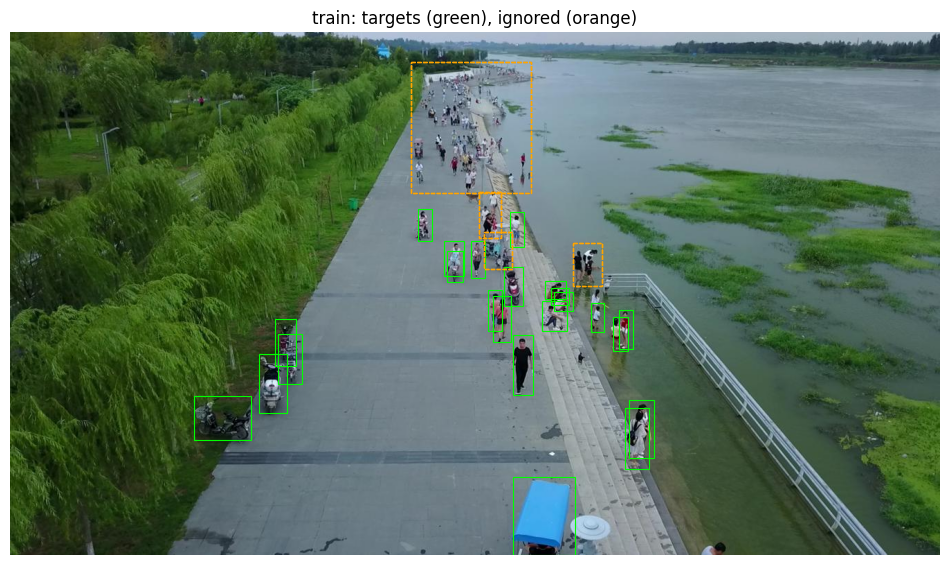

val[10]: image=(3, 756, 1344), targets=36, ignored=0


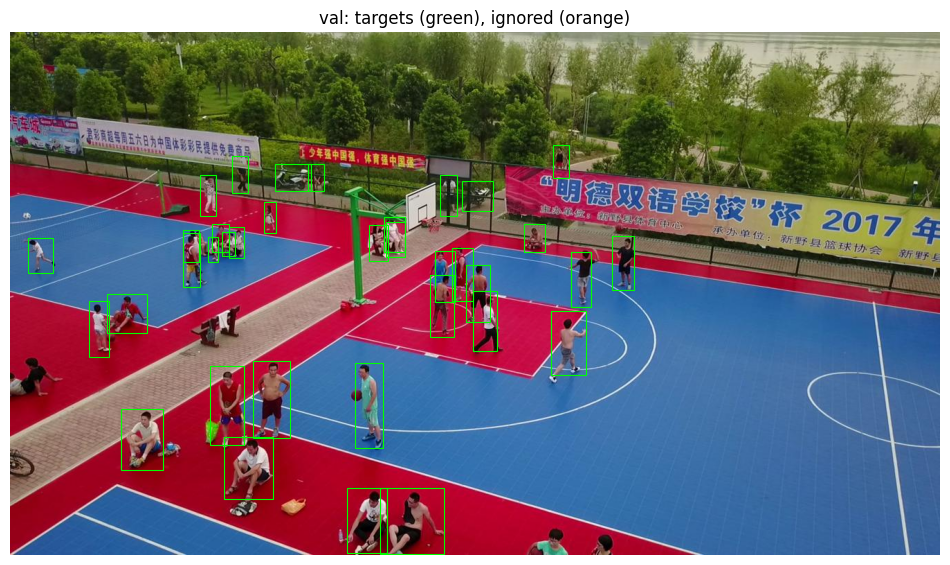

In [12]:
def check_sample(dataset, index=0):
    image, target = dataset[index]
    assert image.ndim == 3 and image.shape[0] == 3
    assert image.dtype == torch.float32
    assert 0 <= float(image.min()) <= float(image.max()) <= 1
    assert target['boxes'].shape == (len(target['labels']), 4)
    assert target['ignored_boxes'].shape[1:] == (4,)
    assert target['boxes'].dtype == torch.float32
    assert target['labels'].dtype == torch.int64

    height, width = image.shape[-2:]
    for key in ('boxes', 'ignored_boxes'):
        boxes = target[key]
        if len(boxes):
            assert bool((boxes[:, 2:] > boxes[:, :2]).all()), f'Invalid {key}'
            assert bool(((boxes[:, [0, 2]] >= 0) & (boxes[:, [0, 2]] <= width)).all())
            assert bool(((boxes[:, [1, 3]] >= 0) & (boxes[:, [1, 3]] <= height)).all())
    if len(target['labels']):
        assert set(target['labels'].tolist()) <= set(CLASS_NAMES)
    print(f'{dataset.split}[{index}]: image={tuple(image.shape)}, '
          f'targets={len(target["boxes"])}, ignored={len(target["ignored_boxes"])}')
    return image, target


def show_sample(dataset, index=10, max_boxes=200):
    image, target = check_sample(dataset, index)
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.imshow(image.permute(1, 2, 0).numpy())
    for key, color, style in [('boxes', 'lime', '-'), ('ignored_boxes', 'orange', '--')]:
        for box in target[key][:max_boxes]:
            x1, y1, x2, y2 = box.tolist()
            ax.add_patch(plt.Rectangle(
                (x1, y1), x2-x1, y2-y1,
                fill=False, edgecolor=color, linewidth=0.8, linestyle=style
            ))
    ax.set_title(f'{dataset.split}: targets (green), ignored (orange)')
    ax.axis('off')
    plt.show()

check_sample(train_ds, 10)
check_sample(val_ds, 10)
show_sample(train_ds, 10)
show_sample(val_ds, 10)

## 8. DataLoader Check
`DataLoader` збирає кадри в batches. Оскільки на різних кадрах різна кількість об'єктів, `collate_fn` залишає їхню розмітку окремо. Перевіряємо один batch перед навчанням.

In [13]:
def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    collate_fn=collate_fn, num_workers=0
)
val_loader = DataLoader(
    val_ds, batch_size=1, shuffle=False,
    collate_fn=collate_fn, num_workers=0
)

batch_images, batch_targets = next(iter(train_loader))
print('Batch size:', len(batch_images))
for image, target in zip(batch_images, batch_targets):
    print('Image:', tuple(image.shape), '| Targets:', len(target['boxes']),
          '| Ignored:', len(target['ignored_boxes']))

Batch size: 2
Image: (3, 756, 1344) | Targets: 55 | Ignored: 32
Image: (3, 756, 1344) | Targets: 34 | Ignored: 8


## 9. Preprocessing Summary

Підготовлено спільний Dataset і DataLoader для object detection моделей.

- COCO annotations перетворено з `XYWH` у `XYXY`, збережено 8 цільових класів.
- Ignored regions відокремлено та збережено для подальшого використання.
- Train і validation не мають спільних відеопослідовностей; усі кадри збережено (`FRAME_STEP=1`).
- Зображення перетворюються на RGB Tensor у `[0,1]`. Для train додано horizontal flip.
- Перевірено координати bounding boxes, візуалізації та роботу DataLoader.

Resizing, normalization і врахування ignored regions під час training налаштовуватимуться окремо для кожної моделі.